In [ ]:
# ============================================================
# 01 — DATA COLLECTION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Excel workbook
df=pd.read_excel("/content/Placement_Data_Analytics_2000_Students_Final (1).xlsx")

print("========== DATA COLLECTION ==========")

print("\nDataset loaded successfully!")

========== DATA COLLECTION ==========

Dataset loaded successfully!


In [ ]:
# ============================================================
# 02 — DATA EXPLORATION
# ============================================================

print("========== DATA EXPLORATION ==========")

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
for i, column in enumerate(df.columns, start=1):
    print(i, ":", column)

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
missing_values = df.isnull().sum()
display(
    missing_values[
        missing_values > 0
    ]
)

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nPlacement Distribution:")
placement_distribution = (
    df["Placement_Status"]
    .value_counts()
)
print(placement_distribution)

print("\nDepartment Distribution:")
print(
    df["Department"].value_counts()
)


========== DATA EXPLORATION ==========

Dataset Shape:
(2008, 20)

Column Names:
1 : Student_ID
2 : Gender
3 : Department
4 : SSC_Percentage
5 : HSC_Percentage
6 : Degree_CGPA
7 : Technical_Score
8 : Soft_Skill_Score
9 : Coding_Score
10 : Work_Experience_Years
11 : Internship_Status
12 : Placement_Status
13 : Placement_Year
14 : Placement_Date
15 : Company_Name
16 : Job_Role
17 : Salary_LPA
18 : Primary_Skill
19 : Recruitment_Mode
20 : Job_Location

Data Types:
Student_ID                object
Gender                    object
Department                object
SSC_Percentage           float64
HSC_Percentage           float64
Degree_CGPA              float64
Technical_Score          float64
Soft_Skill_Score         float64
Coding_Score               int64
Work_Experience_Years      int64
Internship_Status         object
Placement_Status          object
Placement_Year             int64
Placement_Date            object
Company_Name              object
Job_Role                  object
Salary

,SSC_Percentage,HSC_Percentage,Degree_CGPA,Technical_Score,Soft_Skill_Score,Coding_Score,Work_Experience_Years,Placement_Year,Salary_LPA
count,2008.000000,1998.000000,2008.000000,2000.000000,2001.000000,2008.000000,2008.000000,2008.000000,1776.000000
mean,72.219452,74.092412,7.205767,70.191000,69.631184,67.682271,0.990040,2025.166833,4.858148
std,9.920521,9.907486,0.969264,14.510093,14.777311,16.488242,1.158965,0.783840,1.624207
min,45.000000,45.000000,5.000000,45.000000,45.000000,40.000000,0.000000,2024.000000,2.200000
25%,65.277500,67.430000,6.530000,58.000000,57.000000,54.000000,0.000000,2025.000000,3.630000
50%,72.320000,74.010000,7.220000,70.000000,70.000000,67.000000,0.000000,2025.000000,4.800000
75%,79.362500,80.887500,7.870000,83.000000,82.000000,83.000000,2.000000,2026.000000,6.002500
max,98.000000,98.000000,9.800000,95.000000,95.000000,95.000000,3.000000,2026.000000,10.590000



Missing Values:


,0
HSC_Percentage,10
Technical_Score,8
Soft_Skill_Score,7
Company_Name,5
Salary_LPA,232
Primary_Skill,6



Duplicate Records:
0

Placement Distribution:
Placement_Status
Placed        1776
Not Placed     232
Name: count, dtype: int64

Department Distribution:
Department
CS    390
AI    314
EC    225
DS    206
IT    198
EE    195
ME    182
CV    160
AG    138
Name: count, dtype: int64


In [ ]:
# ============================================================
# 03 — DATA CLEANING
# ============================================================
missing_values = df.isnull().sum()
print("Missing values in each column:")
print(missing_values)

duplicates = df[df.duplicated(keep=False)]

print("Duplicate records:")
print(duplicates)
df["SSC_Percentage"] = df["SSC_Percentage"].fillna(
    df["SSC_Percentage"].median())

df["HSC_Percentage"] = df["HSC_Percentage"].fillna(
    df["HSC_Percentage"].median())

df["Degree_CGPA"] = df["Degree_CGPA"].fillna(
    df["Degree_CGPA"].median())

df["Technical_Score"] = df["Technical_Score"].fillna(
    df["Technical_Score"].median())

df["Soft_Skill_Score"] = df["Soft_Skill_Score"].fillna(
    df["Soft_Skill_Score"].median())

df["Coding_Score"] = df["Coding_Score"].fillna(
    df["Coding_Score"].median())

df["Gender"] = df["Gender"].fillna(
    df["Gender"].mode()[0])

df["Department"] = df["Department"].fillna(
    df["Department"].mode()[0])

df["Primary_Skill"] = df["Primary_Skill"].fillna(
    df["Primary_Skill"].mode()[0])

df["Internship_Status"] = df["Internship_Status"].fillna(
    df["Internship_Status"].mode()[0])

Missing values in each column:
Student_ID                 0
Gender                     0
Department                 0
SSC_Percentage             0
HSC_Percentage            10
Degree_CGPA                0
Technical_Score            8
Soft_Skill_Score           7
Coding_Score               0
Work_Experience_Years      0
Internship_Status          0
Placement_Status           0
Placement_Year             0
Placement_Date             0
Company_Name               5
Job_Role                   0
Salary_LPA               232
Primary_Skill              6
Recruitment_Mode           0
Job_Location               0
dtype: int64
Duplicate records:
Empty DataFrame
Columns: [Student_ID, Gender, Department, SSC_Percentage, HSC_Percentage, Degree_CGPA, Technical_Score, Soft_Skill_Score, Coding_Score, Work_Experience_Years, Internship_Status, Placement_Status, Placement_Year, Placement_Date, Company_Name, Job_Role, Salary_LPA, Primary_Skill, Recruitment_Mode, Job_Location]
Index: []


In [ ]:
df = df.drop_duplicates()

print("Duplicate records after cleaning:",
      df.duplicated().sum())

df["Gender"] = df["Gender"].str.strip().str.upper()

df["Department"] = df["Department"].str.strip().str.upper()

df["Placement_Status"] = (
    df["Placement_Status"]
    .str.strip()
    .str.title()
)

df["Primary_Skill"] = (
    df["Primary_Skill"]
    .str.strip()
)

df["Placement_Date"] = pd.to_datetime(
    df["Placement_Date"],
    errors="coerce"
)

print("Data cleaning completed successfully.")

Duplicate records after cleaning: 0
Data cleaning completed successfully.


/tmp/ipykernel_1405/2437763817.py:21: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Placement_Date"] = pd.to_datetime(


In [ ]:
# ============================================================
# 03 — DATA PREPROCESSING
# ============================================================

clean_df = df.copy()

clean_df["Academic_Average"] = (
    clean_df[
        [
            "SSC_Percentage",
            "HSC_Percentage",
            "Degree_CGPA"
        ]
    ].mean(axis=1)
)

clean_df["Technical_Average"] = (
    clean_df["Technical_Score"]
)

clean_df["Soft_Skill_Average"] = (
    clean_df["Soft_Skill_Score"]
)

clean_df["Coding_Average"] = (
    clean_df["Coding_Score"]
)

clean_df["Experience_Index"] = (
    clean_df["Work_Experience_Years"] * 10
    +
    (
        clean_df["Internship_Status"]
        .astype(str)
        .str.lower()
        .eq("completed")
        .astype(int) * 5
    )
)

print("\nPreprocessed Features:")

display(
    clean_df[
        [
            "Student_ID",
            "Department",
            "Academic_Average",
            "Technical_Average",
            "Soft_Skill_Average",
            "Coding_Average",
            "Experience_Index"
        ]
    ].head(10)
)

print("========== DATA PREPROCESSING COMPLETED ==========")


Preprocessed Features:


,Student_ID,Department,Academic_Average,Technical_Average,Soft_Skill_Average,Coding_Average,Experience_Index
0,23B11EC001,EC,54.866667,85.0,51.0,56,5
1,24B11IT001,IT,57.716667,57.0,85.0,74,5
2,25B11CV001,CV,45.816667,80.0,65.0,94,5
3,23B11AI001,AI,49.663333,53.0,60.0,40,5
4,24B11CS001,CS,46.616667,91.0,64.0,89,35
5,25B11CS001,CS,55.196667,58.0,87.0,89,5
6,23B11CS001,CS,55.116667,95.0,88.0,75,0
7,24B11DS001,DS,52.526667,56.0,91.0,54,15
8,25B11AI001,AI,51.683333,76.0,94.0,58,25
9,23B11AG001,AG,61.040000,82.0,63.0,90,5


========== DATA PREPROCESSING COMPLETED ==========


In [ ]:
# ============================================================
# 05 — DATA ANALYSIS
# ============================================================

print("========== DATA ANALYSIS ==========")


# ------------------------------------------------------------
# 1. PLACEMENT ANALYSIS
# ------------------------------------------------------------

placement_distribution = (
    clean_df["Placement_Status"]
    .value_counts()
)

print("\nPlacement Distribution:")
print(placement_distribution)

placed_students = (
    clean_df["Placement_Status"]
    .astype(str)
    .str.lower()
    .eq("placed")
    .sum()
)

total_students = len(clean_df)

placement_rate = (
    placed_students / total_students
) * 100

print(
    f"\nOverall Placement Rate: "
    f"{placement_rate:.2f}%"
)




========== DATA ANALYSIS ==========

Placement Distribution:
Placement_Status
Placed        1776
Not Placed     232
Name: count, dtype: int64

Overall Placement Rate: 88.45%


In [ ]:
# ------------------------------------------------------------
# 2. DEPARTMENT ANALYSIS
# ------------------------------------------------------------
department_analysis = (
    clean_df
    .groupby("Department")
    .agg(
        Students=("Student_ID", "count"),
        Average_CGPA=(
            "Degree_CGPA",
            "mean"
        ),
        Average_Technical=(
            "Technical_Average",
            "mean"
        ),
        Average_Coding=(
            "Coding_Average",
            "mean"
        ),
        Placement_Rate=(
            "Placement_Status",
            lambda x:
            x.astype(str)
            .str.lower()
            .eq("placed")
            .mean() * 100
        ),
        Average_Package=(
            "Salary_LPA",
            "mean"
        )
    )
    .reset_index()
)
print("\nDepartment Analysis:")
display(department_analysis)



Department Analysis:


,Department,Students,Average_CGPA,Average_Technical,Average_Coding,Placement_Rate,Average_Package
0,AG,138,7.226667,69.188406,69.753623,92.028986,4.906220
1,AI,314,7.181688,70.264331,66.703822,88.535032,4.764137
2,CS,390,7.253769,70.723077,68.046154,88.461538,4.782957
3,CV,160,7.326812,71.418750,67.468750,88.750000,4.857958
4,DS,206,7.069078,69.223301,67.092233,85.436893,5.003011
5,EC,225,7.145333,67.440000,67.435556,86.666667,5.091333
6,EE,195,7.189538,70.338462,66.800000,86.153846,4.813393
7,IT,198,7.240000,72.474747,68.984848,92.424242,4.767158
8,ME,182,7.231758,70.450549,67.708791,89.010989,4.853210


In [ ]:


# ------------------------------------------------------------
# 3. SKILL ANALYSIS
# ------------------------------------------------------------
skill_analysis = (
    clean_df
    .groupby("Primary_Skill")
    .agg(
        Students=(
            "Student_ID",
            "count"
        ),

        Average_Technical=(
            "Technical_Score",
            "mean"
        ),

        Average_Coding=(
            "Coding_Score",
            "mean"
        ),

        Placement_Rate=(
            "Placement_Status",
            lambda x:
            x.astype(str)
            .str.lower()
            .eq("placed")
            .mean() * 100
        )
    )
    .sort_values(
        "Placement_Rate",
        ascending=False
    ))
print("\nSkill Analysis:")
display(skill_analysis)





Skill Analysis:


,Students,Average_Technical,Average_Coding,Placement_Rate
Primary_Skill,,,,
Python,246,71.016260,68.821138,91.056911
Data Analytics,257,69.412451,68.778210,90.661479
C++,220,71.600000,66.740909,90.000000
Machine Learning,259,68.772201,68.332046,88.803089
Web Development,247,70.327935,66.538462,88.663968
Cloud Computing,253,71.063241,67.853755,88.537549
SQL,247,70.534413,67.635628,86.639676
Java,279,69.164875,66.706093,83.870968


In [ ]:


# ------------------------------------------------------------
# 4. COMPANY ANALYSIS
# ------------------------------------------------------------

placed_df = clean_df[
    clean_df["Placement_Status"]
    .astype(str)
    .str.lower()
    .eq("placed")
]

company_analysis = (
    placed_df
    .groupby("Company_Name")
    .agg(
        Students_Placed=(
            "Student_ID",
            "count"
        ),

        Average_Package=(
            "Salary_LPA",
            "mean"
        ),

        Highest_Package=(
            "Salary_LPA",
            "max"
        )
    )
    .sort_values(
        "Students_Placed",
        ascending=False
    )
)
print("\nCompany Analysis:")
display(company_analysis)





Company Analysis:


,Students_Placed,Average_Package,Highest_Package
Company_Name,,,
Deloitte,201,4.910050,9.76
Cognizant,201,4.797313,8.92
HCL,193,4.863523,10.18
IBM,177,4.627740,9.26
Tech Mahindra,175,4.937600,9.22
Capgemini,175,4.988857,10.59
TCS,174,4.773851,9.28
Wipro,165,4.834606,9.40
Infosys,158,4.891519,9.09


In [ ]:


# ------------------------------------------------------------
# 5. PACKAGE ANALYSIS
# ------------------------------------------------------------

print("\n========== PACKAGE ANALYSIS ==========")

average_package = (
    placed_df["Salary_LPA"].mean()
)

highest_package = (
    placed_df["Salary_LPA"].max()
)

lowest_package = (
    placed_df["Salary_LPA"].min()
)

print(
    f"Average Package: "
    f"{average_package:.2f} LPA"
)

print(
    f"Highest Package: "
    f"{highest_package:.2f} LPA"
)

print(
    f"Lowest Package: "
    f"{lowest_package:.2f} LPA"
)




========== PACKAGE ANALYSIS ==========
Average Package: 4.86 LPA
Highest Package: 10.59 LPA
Lowest Package: 2.20 LPA


In [ ]:


# ------------------------------------------------------------
# 6. JOB ROLE ANALYSIS
# ------------------------------------------------------------

role_analysis = (
    placed_df
    .groupby("Job_Role")
    .agg(
        Students_Placed=(
            "Student_ID",
            "count"
        ),

        Average_Package=(
            "Salary_LPA",
            "mean"
        )
    )
    .sort_values(
        "Students_Placed",
        ascending=False
    )
)

print("\nJob Role Analysis:")
display(role_analysis)


print("\n========== DATA ANALYSIS COMPLETED ==========")


Job Role Analysis:


,Students_Placed,Average_Package
Job_Role,,
System Engineer,271,4.971734
Cloud Engineer,270,4.880741
Network Engineer,260,4.749500
QA Engineer,258,4.673876
Data Analyst,242,5.037810
Software Engineer,242,4.830661
Business Analyst,233,4.867082



========== DATA ANALYSIS COMPLETED ==========


========== VISUALIZATION ==========


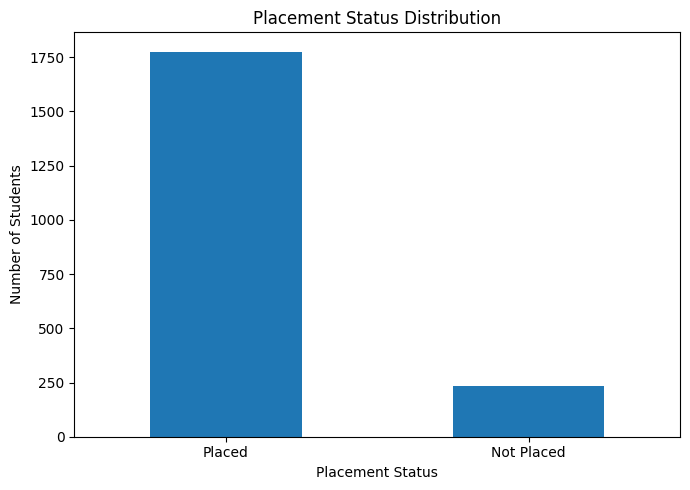

In [ ]:
# ============================================================
# 06 — VISUALIZATION
# ============================================================

print("========== VISUALIZATION ==========")


# --------------------------------------------------
# 1. BAR CHART — PLACEMENT DISTRIBUTION
# --------------------------------------------------

plt.figure(figsize=(7, 5))

clean_df["Placement_Status"].value_counts().plot(
    kind="bar"
)

plt.title("Placement Status Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()




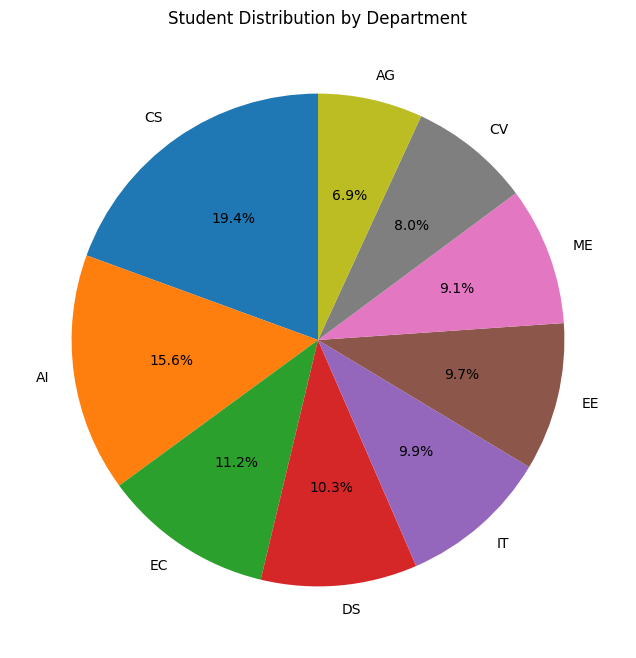

In [ ]:
# ------------------------------------------------------------
# 2. PIE CHART — DEPARTMENT DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(8, 8))

clean_df["Department"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Student Distribution by Department")
plt.ylabel("")

plt.show()



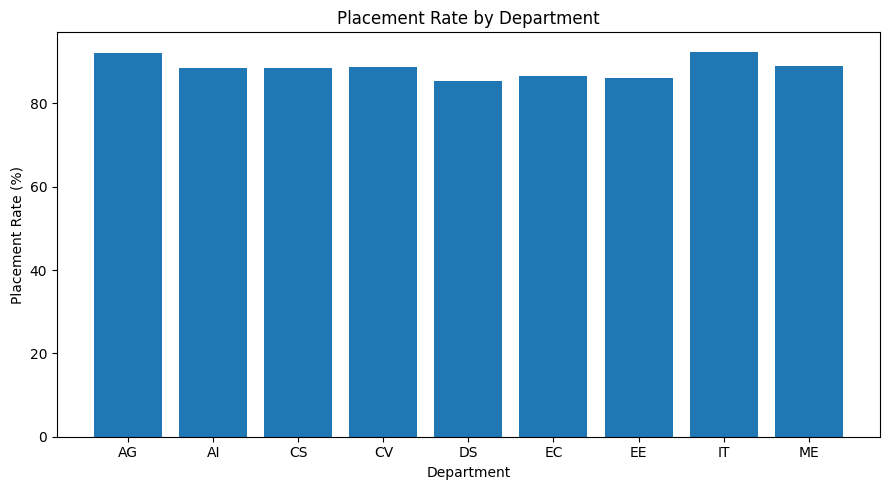

In [ ]:


# ------------------------------------------------------------
# 3. BAR CHART — PLACEMENT RATE BY DEPARTMENT
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    department_analysis["Department"],
    department_analysis["Placement_Rate"]
)

plt.title("Placement Rate by Department")
plt.xlabel("Department")
plt.ylabel("Placement Rate (%)")

plt.tight_layout()
plt.show()


Skill-wise Placement Rate:


,Primary_Skill,Placement_Rate
0,C++,90.000000
1,Cloud Computing,88.537549
2,Data Analytics,90.661479
3,Java,83.870968
4,Machine Learning,88.803089
5,Python,91.056911
6,SQL,86.639676
7,Web Development,88.663968


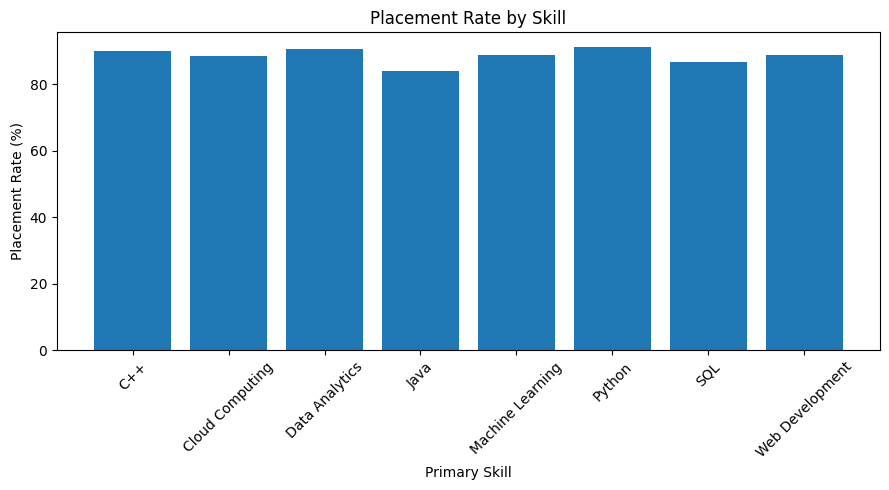

In [ ]:

# ============================================================
# 4.SKILL ANALYTICS
# ============================================================

skill_analysis = (
    clean_df.groupby("Primary_Skill")["Placement_Status"]
    .apply(
        lambda x: x.astype(str)
        .str.lower()
        .eq("placed")
        .mean() * 100
    )
    .reset_index(name="Placement_Rate")
)

print("Skill-wise Placement Rate:")
display(skill_analysis)
# =======================================
# 4.PLACEMENT RATE BY SKILL
# =======================================
plt.figure(figsize=(9, 5))

plt.bar(
    skill_analysis["Primary_Skill"],
    skill_analysis["Placement_Rate"]
)

plt.title("Placement Rate by Skill")
plt.xlabel("Primary Skill")
plt.ylabel("Placement Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


Company-wise Placement:


,Company_Name,Placed_Students
0,Deloitte,201
1,Cognizant,201
2,HCL,193
3,IBM,177
4,Tech Mahindra,175
5,Capgemini,175
6,TCS,174
7,Wipro,165
8,Infosys,158
9,Accenture,152


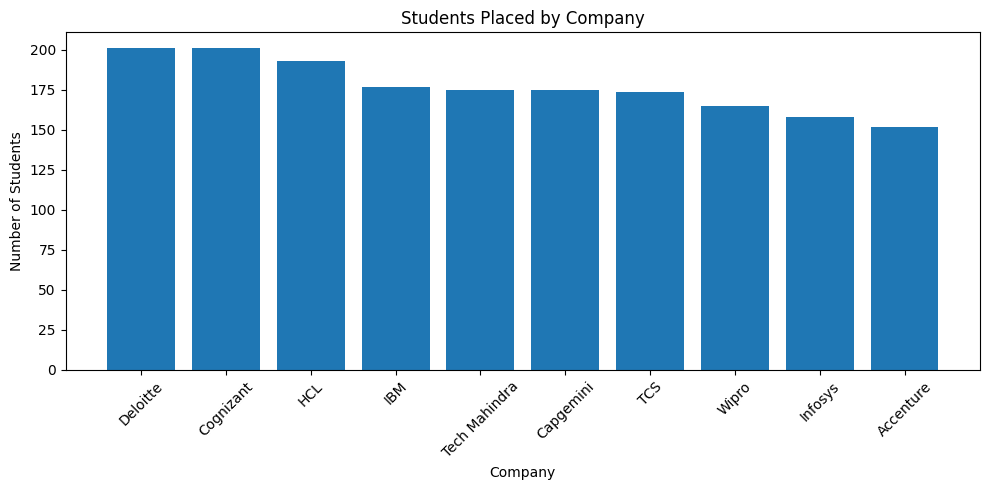

In [ ]:

# ==========================================
# 5. COMPANY ANALYTICS
# ==========================================

company_analysis = (
    placed_df["Company_Name"]
    .value_counts()
    .reset_index()
)

company_analysis.columns = [
    "Company_Name",
    "Placed_Students"
]

print("Company-wise Placement:")
display(company_analysis)

plt.figure(figsize=(10, 5))

plt.bar(
    company_analysis["Company_Name"],
    company_analysis["Placed_Students"]
)

plt.title("Students Placed by Company")
plt.xlabel("Company")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


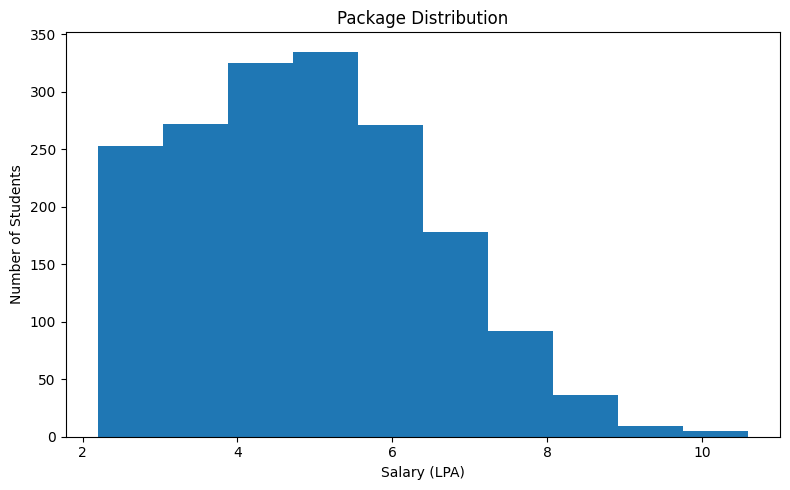

In [ ]:

# ====================================
# 6. PACKAGE DISTRIBUTION
# ====================================

plt.figure(figsize=(8, 5))

plt.hist(
    placed_df["Salary_LPA"],
    bins=10
)

plt.title("Package Distribution")
plt.xlabel("Salary (LPA)")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()


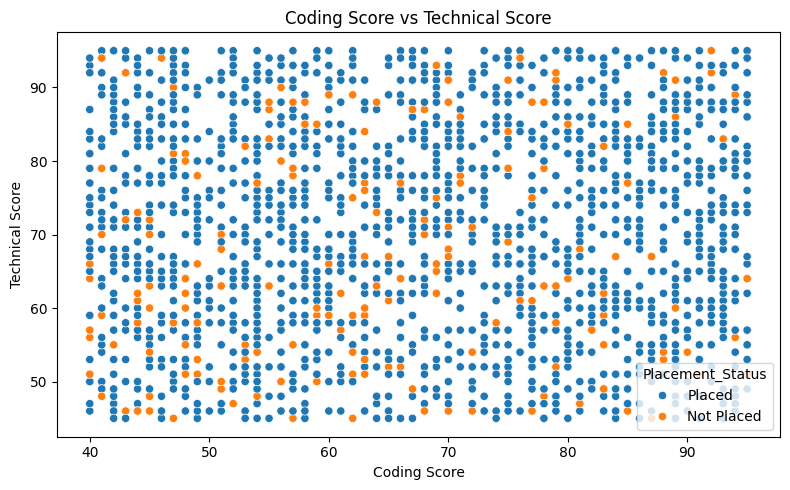

In [ ]:

# ------------------------------------------------------------
# 7. SCATTER PLOT — CODING VS TECHNICAL SCORE
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=clean_df,
    x="Coding_Score",
    y="Technical_Score",
    hue="Placement_Status"
)

plt.title("Coding Score vs Technical Score")
plt.xlabel("Coding Score")
plt.ylabel("Technical Score")

plt.tight_layout()
plt.show()



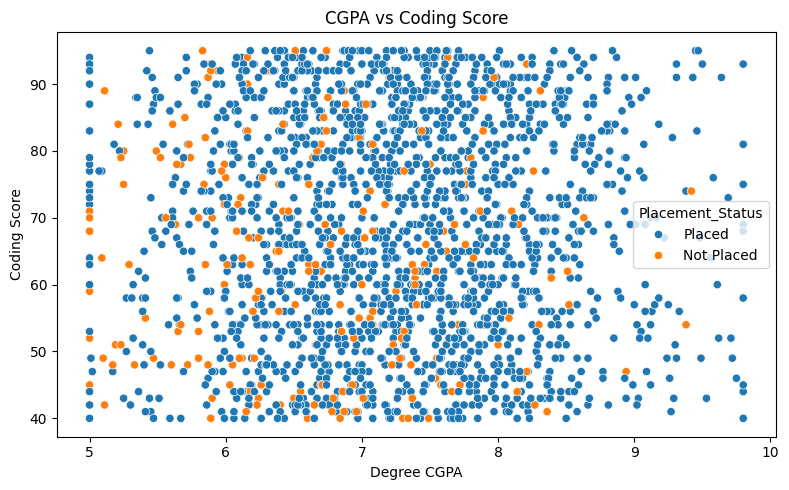

In [ ]:


# --------------------------------------------------
# 8. SCATTER PLOT — CGPA VS CODING SCORE
# --------------------------------------------------

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=clean_df,
    x="Degree_CGPA",
    y="Coding_Score",
    hue="Placement_Status"
)

plt.title("CGPA vs Coding Score")
plt.xlabel("Degree CGPA")
plt.ylabel("Coding Score")

plt.tight_layout()
plt.show()





Year-wise Placement Rate:


,Placement_Year,Placement_Rate
0,2024,87.631027
1,2025,87.899861
2,2026,89.408867


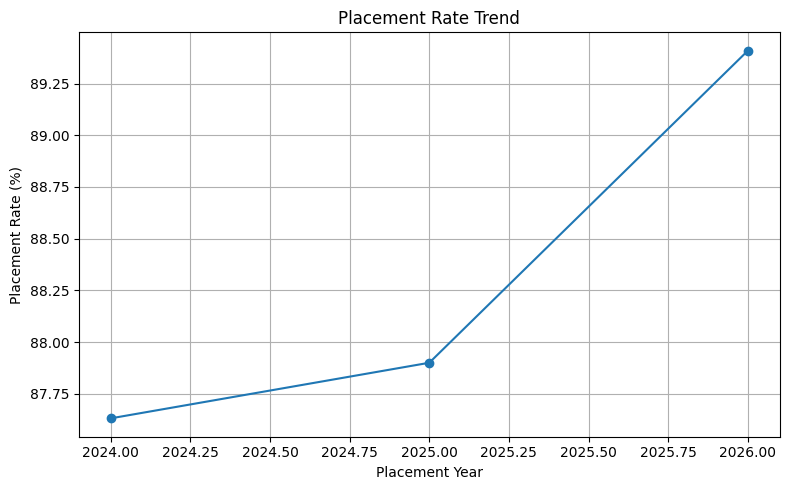

In [ ]:

# ------------------------------------------------------------
# 9. PLACEMENT RATE TREND
# ------------------------------------------------------------

year_analysis = (
    clean_df
    .groupby("Placement_Year")
    .agg(
        Placement_Rate=(
            "Placement_Status",
            lambda x:
            x.astype(str)
            .str.lower()
            .eq("placed")
            .mean() * 100
        )
    )
    .reset_index()
)

print("\nYear-wise Placement Rate:")
display(year_analysis)


plt.figure(figsize=(8, 5))

plt.plot(
    year_analysis["Placement_Year"],
    year_analysis["Placement_Rate"],
    marker="o"
)

plt.title("Placement Rate Trend")
plt.xlabel("Placement Year")
plt.ylabel("Placement Rate (%)")

plt.grid(True)

plt.tight_layout()
plt.show()





Year-wise Average Package:


,Placement_Year,Salary_LPA
0,2024,4.721148
1,2025,4.919953
2,2026,4.883223


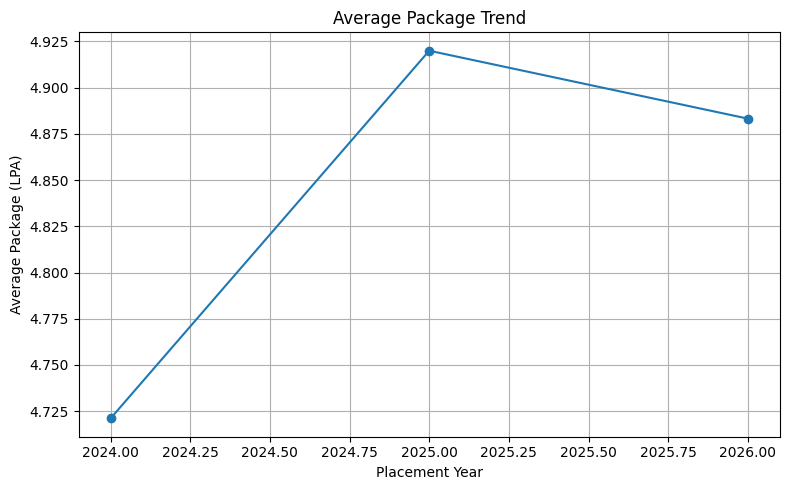


========== VISUALIZATION COMPLETED ==========


In [ ]:


# ------------------------------------------------------------
# 10. AVERAGE PACKAGE TREND
# ------------------------------------------------------------

salary_trend = (
    placed_df
    .groupby("Placement_Year")["Salary_LPA"]
    .mean()
    .reset_index()
)

print("\nYear-wise Average Package:")
display(salary_trend)

plt.figure(figsize=(8, 5))

plt.plot(
    salary_trend["Placement_Year"],
    salary_trend["Salary_LPA"],
    marker="o"
)

plt.title("Average Package Trend")
plt.xlabel("Placement Year")
plt.ylabel("Average Package (LPA)")

plt.grid(True)

plt.tight_layout()
plt.show()

print("\n========== VISUALIZATION COMPLETED ==========")

In [ ]:
print(clean_df.columns.tolist())

['Student_ID', 'Gender', 'Department', 'SSC_Percentage', 'HSC_Percentage', 'Degree_CGPA', 'Technical_Score', 'Soft_Skill_Score', 'Coding_Score', 'Work_Experience_Years', 'Internship_Status', 'Placement_Status', 'Placement_Year', 'Placement_Date', 'Company_Name', 'Job_Role', 'Salary_LPA', 'Primary_Skill', 'Recruitment_Mode', 'Job_Location', 'Academic_Average', 'Technical_Average', 'Soft_Skill_Average', 'Coding_Average', 'Experience_Index']


In [ ]:
# ============================================================
# 07 — INSIGHTS
# ============================================================

print("========== FINAL INSIGHTS ==========")


# Create placed student dataset
placed_df = clean_df[
    clean_df["Placement_Status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("placed")
]


# ------------------------------------------------------------
# 1. PLACEMENT RATE
# ------------------------------------------------------------

total_students = len(clean_df)

placed_students = len(placed_df)

placement_rate = (
    placed_students / total_students
) * 100

print(
    f"Placement Rate: "
    f"{placement_rate:.2f}%"
)





========== FINAL INSIGHTS ==========
Placement Rate: 88.45%


In [ ]:
# ---------------------------------------------
# 2. PACKAGE INSIGHTS
# ---------------------------------------------

average_package = (
    placed_df["Salary_LPA"].mean()
)

highest_package = (
    placed_df["Salary_LPA"].max()
)

lowest_package = (
    placed_df["Salary_LPA"].min()
)

print(
    f"Average Package: "
    f"{average_package:.2f} LPA"
)

print(
    f"Highest Package: "
    f"{highest_package:.2f} LPA"
)

print(
    f"Lowest Package: "
    f"{lowest_package:.2f} LPA"
)




Average Package: 4.86 LPA
Highest Package: 10.59 LPA
Lowest Package: 2.20 LPA


In [ ]:
# ------------------------------------------------------------
# 3. COMPANY INSIGHTS
# ------------------------------------------------------------

top_company = (
    placed_df["Company_Name"]
    .value_counts()
    .idxmax()
)
print("COMPANY INSIGHTS:")
print(
    "Top Recruiting Company:",
    top_company
)


COMPANY INSIGHTS:
Top Recruiting Company: Deloitte


In [ ]:
# ------------------------------------------------------------
# 4. ROLE INSIGHTS
# ------------------------------------------------------------

top_role = (
    placed_df["Job_Role"]
    .value_counts()
    .idxmax()
)
print("ROLE INSIGHTS")
print(
    "Most Common Job Role:",
    top_role
)


ROLE INSIGHTS
Most Common Job Role: System Engineer


In [ ]:
# ------------------------------------------------------------
# 5. DEPARTMENT INSIGHTS
# ------------------------------------------------------------
department_analysis = (
    clean_df
    .groupby("Department")
    .agg(
        Placement_Rate=(
            "Placement_Status",
            lambda x:
            x.astype(str)
            .str.strip()
            .str.lower()
            .eq("placed")
            .mean() * 100
        )
    )
    .reset_index())
best_department = (
    department_analysis.loc[
        department_analysis["Placement_Rate"].idxmax(),
        "Department"
    ]
)

best_department_rate = (
    department_analysis["Placement_Rate"].max()
)
print("DEPARTMENT INSIGHTS")
print(
    "Best Placement Department:",
    best_department
)

print(
    f"Department Placement Rate: "
    f"{best_department_rate:.2f}%")


DEPARTMENT INSIGHTS
Best Placement Department: IT
Department Placement Rate: 92.42%


In [ ]:
# ------------------------------------------------------------
# 6. SKILL INSIGHTS
# ------------------------------------------------------------

# Create skill analysis
skill_analysis = (
    clean_df
    .groupby("Primary_Skill")
    .agg(
        Placement_Rate=(
            "Placement_Status",
            lambda x:
            x.astype(str)
            .str.strip()
            .str.lower()
            .eq("placed")
            .mean() * 100
        )
    )
    .sort_values(
        "Placement_Rate",
        ascending=False
    )
)

top_skill = (
    skill_analysis.index[0]
)
print("SKILL INSIGHTS:")
print(
    "Top Placement Skill:",
    top_skill
)

SKILL INSIGHTS:
Top Placement Skill: Python


In [ ]:
# ============================================
# FINAL DATASET SUMMARY
# Placement Dataset — Key Statistics
# ============================================

# Basic dataset statistics
total_records = len(df)
total_attributes = len(df.columns)

# Department statistics
total_departments = df["Department"].nunique()

# Primary skill statistics
unique_skills = df["Primary_Skill"].nunique()

# Academic and skill averages
average_ssc = df["SSC_Percentage"].mean()
average_hsc = df["HSC_Percentage"].mean()
average_degree_cgpa = df["Degree_CGPA"].mean()
average_technical_score = df["Technical_Score"].mean()
average_soft_skill_score = df["Soft_Skill_Score"].mean()
average_coding_score = df["Coding_Score"].mean()

# Placement statistics
placement_counts = df["Placement_Status"].value_counts()

placed_students = placement_counts.get("Placed", 0)
not_placed_students = placement_counts.get("Not Placed", 0)

overall_placement_rate = (placed_students / total_records) * 100

# Salary statistics
average_package = df["Salary_LPA"].mean()
highest_package = df["Salary_LPA"].max()
lowest_package = df["Salary_LPA"].min()

# Top recruiting company
company_counts = df["Company_Name"].dropna().value_counts()
top_company = company_counts.idxmax()

# Most common job role
role_counts = df["Job_Role"].dropna().value_counts()
most_common_role = role_counts.idxmax()

# Top placement skill
skill_placement = df[
    df["Placement_Status"] == "Placed"
]["Primary_Skill"].dropna()

skill_counts = skill_placement.value_counts()
top_placement_skill = skill_counts.idxmax()

# Best placement department
department_placement = (
    df.groupby("Department")["Placement_Status"]
      .apply(lambda x: (x == "Placed").mean() * 100)
)

best_department = department_placement.idxmax()
best_department_rate = department_placement.max()


# ============================================
# DISPLAY FINAL DATASET SUMMARY
# ============================================

print("=" * 50)
print("       PLACEMENT DATASET - KEY STATISTICS")
print("=" * 50)

print(f"Total Records              : {total_records}")
print(f"Total Attributes           : {total_attributes}")
print(f"Number of Departments      : {total_departments}")
print(f"Unique Primary Skills      : {unique_skills}")

print(f"Average SSC Percentage     : {average_ssc:.2f}%")
print(f"Average HSC Percentage     : {average_hsc:.2f}%")
print(f"Average Degree CGPA        : {average_degree_cgpa:.2f}")
print(f"Average Technical Score    : {average_technical_score:.2f}")
print(f"Average Soft Skill Score   : {average_soft_skill_score:.2f}")
print(f"Average Coding Score       : {average_coding_score:.2f}")

print(f"Overall Placement Rate     : {overall_placement_rate:.2f}%")
print(f"Placed Students            : {placed_students}")
print(f"Not Placed Students        : {not_placed_students}")

print(f"Average Package            : {average_package:.2f} LPA")
print(f"Highest Package            : {highest_package:.2f} LPA")
print(f"Lowest Package             : {lowest_package:.2f} LPA")

print(f"Top Recruiting Company     : {top_company}")
print(f"Most Common Job Role       : {most_common_role}")
print(f"Top Placement Skill        : {top_placement_skill}")
print(f"Best Placement Department  : {best_department} — {best_department_rate:.2f}%")

print("=" * 50)

       PLACEMENT DATASET - KEY STATISTICS
Total Records              : 2008
Total Attributes           : 20
Number of Departments      : 9
Unique Primary Skills      : 8
Average SSC Percentage     : 72.22%
Average HSC Percentage     : 74.09%
Average Degree CGPA        : 7.21
Average Technical Score    : 70.19
Average Soft Skill Score   : 69.63
Average Coding Score       : 67.68
Overall Placement Rate     : 88.45%
Placed Students            : 1776
Not Placed Students        : 232
Average Package            : 4.86 LPA
Highest Package            : 10.59 LPA
Lowest Package             : 2.20 LPA
Top Recruiting Company     : Not Applicable
Most Common Job Role       : System Engineer
Top Placement Skill        : Java
Best Placement Department  : IT — 92.42%
